# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [3]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710

Reporte de clasificacion:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



notebooks\lecture6\challenge\03_evaluation_deployment_challenge.ipynb:cell6:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


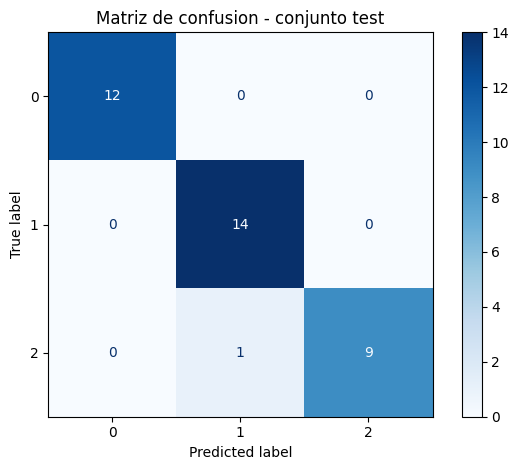

In [4]:
y_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_pred)
test_f1_macro = f1_score(y_test, y_pred, average="macro")

print(f"Accuracy test: {test_accuracy:.4f}")
print(f"F1 macro test: {test_f1_macro:.4f}")
print("\nReporte de clasificacion:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
)
plt.title("Matriz de confusion - conjunto test")
plt.tight_layout()
plt.show()

**Analisis:**

El accuracy de test es **0.9722**, cercano al accuracy medio de validacion cruzada (**0.9791**); la diferencia es de unos 0.0068, sin una brecha grande que indique sobreajuste claro en esta particion. La matriz de confusion muestra una observacion de la clase 2 predicha como clase 1; las observaciones de la clase 0 se clasificaron correctamente. El test tiene solo 36 casos, asi que las metricas tienen incertidumbre y no deben interpretarse como una garantia de rendimiento futuro.

## 3. Función de inferencia

In [5]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve prediccion y probabilidad por clase."""
    missing = [column for column in feature_columns if column not in records.columns]
    if missing:
        raise ValueError(f"Faltan columnas requeridas: {missing}")

    ordered_records = records.loc[:, feature_columns]
    predictions = model.predict(ordered_records)
    probabilities = model.predict_proba(ordered_records)

    result = pd.DataFrame({"prediction": predictions}, index=records.index)
    for position, class_label in enumerate(model.classes_):
        result[f"probability_class_{class_label}"] = probabilities[:, position]
    return result

## 4. Predicción por lotes

In [6]:
# Simulacion de datos nuevos. En produccion no provendrian del test set.
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_output = pd.concat(
    [new_records.reset_index(drop=True), batch_predictions.reset_index(drop=True)],
    axis=1,
)
batch_output.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print(batch_output.to_string(index=False))

 alcohol  malic_acid  ash  alcalinity_of_ash  magnesium  total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity  hue  od280/od315_of_diluted_wines  proline  prediction  probability_class_0  probability_class_1  probability_class_2
   14.10        2.16 2.30               18.0      105.0           2.95        3.32                  0.22             2.38             5.75 1.25                          3.17   1510.0           0             0.999671             0.000307             0.000023
   12.51        1.24 2.25               17.5       85.0           2.00        0.58                  0.60             1.25             5.45 0.75                          1.51    650.0           1             0.007051             0.540423             0.452526
   13.87        1.90 2.80               19.4      107.0           2.95        2.97                  0.37             1.76             4.50 1.25                          3.40    915.0           0             0.992000           

## 5. Reporte final

In [7]:
test_metrics = {
    "model": training_metadata["champion"],
    "accuracy": float(test_accuracy),
    "f1_macro": float(test_f1_macro),
    "cv_accuracy": float(training_metadata["best_cv_accuracy"]),
}
(REPORTS_DIR / "test_metrics.json").write_text(
    json.dumps(test_metrics, indent=2),
    encoding="utf-8",
)
print(json.dumps(test_metrics, indent=2))

{
  "model": "logistic_regression",
  "accuracy": 0.9722222222222222,
  "f1_macro": 0.9709618874773139,
  "cv_accuracy": 0.9790640394088669
}


In [8]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeon | `logistic_regression` |
| Accuracy CV | 0.9791 |
| Accuracy test | 0.9722 |
| F1 macro test | 0.9710 |
| Clases mas confundidas | Una observacion de clase 2 se predijo como clase 1 |
| Principal limitacion | El conjunto de test tiene solo 36 observaciones; la estimacion es incierta. |

## Checklist

- [x] Evalue unicamente el modelo campeon.
- [x] No reajuste hiperparametros despues de observar test.
- [x] Implemente validacion basica del esquema de entrada.
- [x] Genere predicciones por lotes.
- [x] Guarde las metricas finales.